# Проект «Исследование гендерного разрыва в оплате труда работодателей Великобритании»

**Данные:** `UK Gender Pay Gap Data - 2025 to 2026.csv` — официальные отчёты работодателей в сервис Gender Pay Gap Service (gov.uk), отчётный год 2025/26.


## 1. Введение и постановка цели

**Цель исследования** - оценить влияние характеристик работодателя (отрасль, сектор экономики, размер, регион, гендерная структура персонала) на величину гендерного разрыва в оплате труда и выделить **три фактора с наибольшим влиянием** на медианный почасовой разрыв по данным отчётов британских работодателей за 2025/26 год.

Для этого необходимо провести анализ статистических данных из более чем 11 тысяч отчётов работодателей Великобритании с численностью персонала от 250 человек.

Результаты исследования могут быть использованы для определения групп работодателей, в которых разрыв в оплате мужчин и женщин наиболее велик. Это поможет заказчикам: государственному регулятору в сфере равенства и HR-подразделениям компаний — адресно направлять проверки, методические рекомендации и программы поддержки. 

Анализ данных должен помочь заказчику принимать более обоснованные решения о том, на какие отрасли и типы работодателей направлять меры по сокращению разрыва. Так ограниченные ресурсы контроля будут расходоваться там, где эффект от них будет наибольшим.

### Описание данных

Одна строка - отчёт одного работодателя. Разрыв считается как **(оплата мужчин − оплата женщин) / оплата мужчин × 100**. Положительное значение означает, что мужчинам платят больше.

**Работодатель**
- `EmployerName` - название организации на момент подачи отчёта
- `EmployerId` - внутренний ID работодателя в сервисе
- `Address` - юридический адрес
- `PostCode` - почтовый индекс
- `CompanyNumber` - номер в реестре компаний Companies House
- `SicCodes` - коды отраслевой классификации SIC (может быть несколько; код `1` метка госсектора)
- `EmployerSize` - интервал численности персонала
- `CurrentName` - текущее название организации

**Разрыв в оплате**
- `DiffMeanHourlyPercent` - разрыв в средней почасовой оплате, %
- `DiffMedianHourlyPercent` - разрыв в медианной почасовой оплате, % (**целевой показатель**)
- `DiffMeanBonusPercent` - разрыв в средних бонусах, %
- `DiffMedianBonusPercent` - разрыв в медианных бонусах, %
- `MaleBonusPercent` / `FemaleBonusPercent` - доля мужчин / женщин, получивших бонус, %

**Квартили оплаты** (сотрудники упорядочены по почасовой ставке и разбиты на 4 равные группы)
- `MaleLowerQuartile` / `FemaleLowerQuartile` - доля мужчин / женщин в нижнем квартиле, %
- `MaleLowerMiddleQuartile` / `FemaleLowerMiddleQuartile` - во втором квартиле
- `MaleUpperMiddleQuartile` / `FemaleUpperMiddleQuartile` - в третьем квартиле
- `MaleTopQuartile` / `FemaleTopQuartile` - в верхнем квартиле

**Сведения об отчёте**
- `CompanyLinkToGPGInfo` - ссылка на пояснения компании к цифрам
- `ResponsiblePerson` - лицо, подтвердившее данные
- `SubmittedAfterTheDeadline` - подан ли отчёт после срока
- `DueDate` - крайний срок подачи
- `DateSubmitted` - дата фактической подачи

**Гипотезы для проверки**

| № | Гипотеза |
|---|---|
| H1 | Чем больше женщин в верхнем квартиле оплаты, тем меньше разрыв |
| H2 | Разрыв зависит от отрасли |
| H3 | В госсекторе разрыв меньше, чем в частном |
| H4 | Разрыв зависит от размера компании |
| H5 | Разрыв в бонусах больше, чем в почасовой оплате |
| H6 | В Лондоне разрыв выше, чем в других регионах |
| H7 | Компании, публикующие пояснения к отчёту, имеют меньший разрыв |

## 2. Предварительный обзор данных

### 2.1 Документация к датасету

**Откуда данные.** Официальная выгрузка государственного сервиса Gender Pay Gap Service (gov.uk), отчётный год 2025/26. Отчётность обязательна по Закону о равенстве 2010 г. и регламентам 2017 г. для всех работодателей Великобритании с численностью **от 250 сотрудников**; компании меньшего размера отчитываются добровольно. Контроль — Комиссия по равенству и правам человека (EHRC).

**Как собирались.**
- Дата снимка — 5 апреля 2025 (частный сектор) или 31 марта 2025 (госсектор). Численность определяется на эту дату, почасовая оплата и квартили — за расчётный период, в который она попадает, а бонусы — за 12 месяцев, заканчивающихся датой снимка.
- Работадатель сам рассчитывает 6 показателей по единой методике: разрыв в средней и медианной почасовой оплате, разрыв в средних и медианных бонусах, доли мужчин и женщин с бонусом, состав четырёх квартилей оплаты.
- Разрыв = (оплата мужчин − оплата женщин) / оплата мужчин × 100%; > 0 — мужчинам платят больше.
- Вручную вносит цифры в онлайн-форму до **4 апреля 2026** (частный) или **30 марта 2026** (госсектор). В частном секторе отчёт подписывает ответственное лицо.
- Отчёт сразу публикуется; ссылка на пояснения компании — по желанию.

**Ограничения.**
- **Нет абсолютных зарплат и точной численности:** только проценты и интервал размера компании; пол — только бинарный.
- **Охват — только крупные работодатели;** добровольные отчёты (< 250 чел.) — самоотбор.
- **Бонусный разрыв** не вычисляется, если один пол бонусов не получал, и ненадёжен на малых группах (до −4900%).
- **Самоотчётность без проверки и свободный ввод:** ошибки в значениях (−757%, −999 999 999), SIC-кодах и индексах.
- **Групповые отчёты** дублируются от каждого юрлица группы; меняется адрес, а не сотрудники и показатели.

### 2.2 Импорт библиотек и загрузка данных

In [211]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)
plt.rcParams['figure.dpi'] = 100
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

data_raw = pd.read_csv('UK Gender Pay Gap Data - 2025 to 2026.csv')
data = data_raw.copy()
print(f'Строк: {data.shape[0]:,}   Столбцов: {data.shape[1]}')

Строк: 11,198   Столбцов: 27


### 2.3 Первые 10 строк

In [212]:
data.head(10)

,EmployerName,EmployerId,Address,PostCode,CompanyNumber,SicCodes,DiffMeanHourlyPercent,DiffMedianHourlyPercent,DiffMeanBonusPercent,DiffMedianBonusPercent,MaleBonusPercent,FemaleBonusPercent,MaleLowerQuartile,FemaleLowerQuartile,MaleLowerMiddleQuartile,FemaleLowerMiddleQuartile,MaleUpperMiddleQuartile,FemaleUpperMiddleQuartile,MaleTopQuartile,FemaleTopQuartile,CompanyLinkToGPGInfo,ResponsiblePerson,EmployerSize,CurrentName,SubmittedAfterTheDeadline,DueDate,DateSubmitted
0,'PRIFYSGOL ABERYSTWYTH' AND 'ABERYSTWYTH UNIVE...,19070,"Aberystwyth University, Penglais, Ceredigion, ...",SY23 3FL,RC000641,NaN,7.97,0.00,NaN,NaN,0.0,0.0,48.30,51.70,40.80,59.20,36.10,63.90,53.00,47.00,https://www.aber.ac.uk/en/equality/equality-re...,Dylan Jones (HR Business Partner (EDI)),1000 to 4999,'PRIFYSGOL ABERYSTWYTH' AND 'ABERYSTWYTH UNIVE...,False,2026/04/05 00:00:00,2026/03/27 13:34:41
1,"""RED BAND"" CHEMICAL COMPANY, LIMITED",16879,"19 Smith's Place, Leith Walk, Edinburgh, EH6 8NU",EH6 8NU,SC016876,47730,-2.91,-0.04,-59.21,-5.26,25.7,74.3,35.70,64.30,28.60,71.40,19.70,80.30,23.90,76.10,NaN,Osmond Ramsay (Managing Director),250 to 499,"""RED BAND"" CHEMICAL COMPANY, LIMITED",False,2026/04/05 00:00:00,2025/05/23 16:29:27
2,10 TRINITY SQUARE HOTEL LIMITED,19455,"5 Market Yard Mews, 194-204 Bermondsey Street,...",SE1 3TQ,08064685,82990,1.60,5.60,-55.20,28.60,32.0,41.7,43.00,57.00,60.00,40.00,58.00,42.00,61.00,39.00,NaN,Neel Kumar (Director of People and CUlture),250 to 499,10 TRINITY SQUARE HOTEL LIMITED,False,2026/04/05 00:00:00,2026/04/03 15:39:35
3,1509 GROUP,15320,"Royal Grammar School, High Street, Guildford, ...",GU1 3BB,04104101,"85200,\n85310",21.48,17.74,NaN,NaN,0.0,0.0,29.00,71.00,35.00,65.00,51.00,49.00,70.00,30.00,http://www.rgsg.co.uk,Rebecca Whitham (Director of Finance and Opera...,250 to 499,1509 GROUP,False,2026/04/05 00:00:00,2026/03/26 09:30:06
4,1LIFE MANAGEMENT SOLUTIONS LIMITED,687,"The Stables, Duxbury Park, Duxbury Hall Road, ...",PR7 4AT,02566586,"93110,\n93130,\n93290",-14.80,-35.00,2.10,54.50,8.8,17.0,53.01,46.99,40.96,59.04,32.93,67.07,27.31,72.69,NaN,Azhar Farooq (Head of Payroll),250 to 499,1LIFE MANAGEMENT SOLUTIONS LIMITED,False,2026/04/05 00:00:00,2026/03/04 10:08:22
5,1ST HOME CARE LTD.,17484,"Suite 1, Ground Floor Academy House, 1346 Shet...",G32 9AT,SC272838,"86900,\n88100",-4.38,-0.06,NaN,NaN,0.0,0.0,16.67,83.33,10.53,89.47,5.56,94.44,10.53,89.47,NaN,David Sargent (Dr),Less than 250,1ST HOME CARE LTD.,False,2026/04/05 00:00:00,2025/05/10 15:39:47
6,1ST LOCATE (UK) LIMITED,46212,"Apson House, Bullerthorpe Lane, Leeds, England...",LS15 9JN,03702599,"63110,\n64999,\n80100",29.13,3.00,41.57,15.00,90.4,85.2,39.60,60.40,45.30,54.70,43.40,56.60,67.90,32.10,NaN,Tracy Channell-Napier (Group Finance Director),250 to 499,1ST LOCATE (UK) LIMITED,False,2026/04/05 00:00:00,2026/03/16 08:55:36
7,2 AGRICULTURE GROWING LIMITED,6290,"Boparan Support Centre Portland House,, Bicken...",B37 7WR,05969169,1470,17.00,8.00,-10.00,-25.00,33.0,65.0,84.00,16.00,90.00,10.00,92.00,8.00,97.00,3.00,NaN,Julie Barrett (HR Manager),1000 to 4999,2 AGRICULTURE GROWING LIMITED,False,2026/04/05 00:00:00,2026/04/02 14:26:51
8,2 AGRICULTURE LIMITED,14399,"Fairview Mill, Ingliston, Newbridge, Midlothia...",EH28 8NB,SC156515,"1470,\n10910",8.60,12.10,19.40,-51.00,90.2,94.0,74.50,25.50,91.50,8.50,96.80,3.20,84.00,16.00,https://www.2agriculture.com/wp-content/upload...,Gavin Berry (Chief Financial Officer),250 to 499,2 AGRICULTURE LIMITED,False,2026/04/05 00:00:00,2026/04/02 10:31:00
9,2 EXCEL (HOLDINGS) LIMITED,21894,"72 Fielding Road, London, England, W4 1DB",W4 1DB,10656583,64209,34.70,33.70,NaN,NaN,0.0,0.0,50.50,49.50,73.30,26.70,81.10,18.90,94.50,5.50,https://www.2excelaviation.com/statement-on-ge...,Louise Campbell (Group HR Director),250 to 499,2 EXCEL (HOLDINGS) LIMITED,False,2026/04/05 00:00:00,2026/04/01 10:31:35


### 2.4 Основная информация

In [213]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11198 entries, 0 to 11197
Data columns (total 27 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   EmployerName               11198 non-null  object 
 1   EmployerId                 11198 non-null  int64  
 2   Address                    11164 non-null  object 
 3   PostCode                   11139 non-null  object 
 4   CompanyNumber              9676 non-null   object 
 5   SicCodes                   10226 non-null  object 
 6   DiffMeanHourlyPercent      11198 non-null  float64
 7   DiffMedianHourlyPercent    11198 non-null  float64
 8   DiffMeanBonusPercent       8451 non-null   float64
 9   DiffMedianBonusPercent     8451 non-null   float64
 10  MaleBonusPercent           11198 non-null  float64
 11  FemaleBonusPercent         11198 non-null  float64
 12  MaleLowerQuartile          11198 non-null  float64
 13  FemaleLowerQuartile        11198 non-null  flo

Файл прочитан корректно: заголовки распознаны, разделитель верный,смещённых столбцов нет. В данных **11 198 строк и 27 столбцов**.

Типы данных:
- 14 показателей разрыва и квартилей - `float64`, это корректно.
- `SubmittedAfterTheDeadline` - `bool`.
- `DueDate` и `DateSubmitted` прочитаны как строки, их нужно перевести в `datetime`.
- `EmployerSize` - строка, по смыслу это размах числа сотрудников.
- В `SicCodes` несколько кодов записаны через запятую с переносом строки.

### 2.5 Пропуски и дубликаты

#### Пропуски

,пропусков,"доля, %"
CompanyLinkToGPGInfo,5209,46.5
DiffMeanBonusPercent,2747,24.5
DiffMedianBonusPercent,2747,24.5
ResponsiblePerson,1949,17.4
CompanyNumber,1522,13.6
SicCodes,972,8.7
PostCode,59,0.5
Address,34,0.3


Столбцов с пропусками: 8 из 27
Всего пропущенных ячеек: 15,239 из 302,346 (5.0%)

Пропусков в ключевых показателях: 0


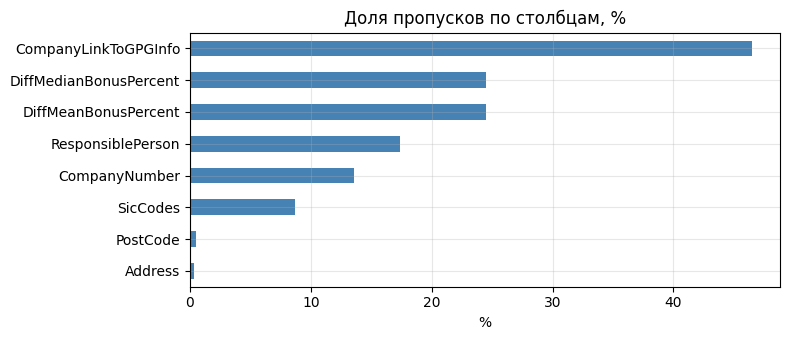

In [214]:
na = data.isna().sum()
na_table = pd.DataFrame({'пропусков': na, 'доля, %': (na / len(data) * 100).round(1)}) \
             .query('пропусков > 0').sort_values('пропусков', ascending=False)
display(na_table)

print(f'Столбцов с пропусками: {len(na_table)} из {data.shape[1]}')
print(f'Всего пропущенных ячеек: {na.sum():,} из {data.size:,} ({na.sum() / data.size * 100:.1f}%)')

key_cols = ['DiffMeanHourlyPercent', 'DiffMedianHourlyPercent',
            'FemaleLowerQuartile', 'FemaleLowerMiddleQuartile', 'FemaleUpperMiddleQuartile', 'FemaleTopQuartile']
print('\nПропусков в ключевых показателях:', data[key_cols].isna().sum().sum())

ax = na_table['доля, %'].sort_values().plot.barh(figsize=(8, 3.5), color='steelblue')
ax.set_title('Доля пропусков по столбцам, %'); ax.set_xlabel('%')
plt.tight_layout(); plt.show()

#### Дубликаты


In [215]:
print('Полных дубликатов строк:', data.duplicated().sum())

print('Повторов EmployerId:', data['EmployerId'].duplicated().sum())
print('Повторов CompanyNumber (без пустых):', data['CompanyNumber'].dropna().duplicated().sum())

name_norm = data['EmployerName'].str.upper().str.strip()
print('Повторов EmployerName:', data['EmployerName'].duplicated().sum(),
      '| без учёта регистра:', name_norm.duplicated().sum())

metrics = data.columns[6:20].tolist()
dup_content = data.duplicated(subset=['PostCode'] + metrics, keep=False)
print('Записей с одинаковым индексом и идентичными показателями:', dup_content.sum(),
      f'(лишних копий: {data.duplicated(subset=["PostCode"] + metrics).sum()})')

display(data.loc[dup_content, ['EmployerName', 'PostCode', 'CompanyNumber',
                               'DiffMeanHourlyPercent', 'DiffMedianHourlyPercent', 'FemaleTopQuartile']]
            .sort_values(['PostCode', 'DiffMeanHourlyPercent']).head(10))

Полных дубликатов строк: 0
Повторов EmployerId: 0
Повторов CompanyNumber (без пустых): 0
Повторов EmployerName: 1 | без учёта регистра: 1
Записей с одинаковым индексом и идентичными показателями: 92 (лишних копий: 51)


,EmployerName,PostCode,CompanyNumber,DiffMeanHourlyPercent,DiffMedianHourlyPercent,FemaleTopQuartile
4207,HALLIBURTON ENERGY SERVICES LIMITED,AB21 0GN,SC231879,12.00,11.00,11.00
4208,HALLIBURTON MANAGEMENT LIMITED,AB21 0GN,SC232078,12.00,11.00,11.00
1997,CHRISTADELPHIAN CARE HOMES,B27 6AD,NaN,8.42,1.02,68.80
1998,CHRISTADELPHIAN CARE HOMES,B27 6AD,15346809,8.42,1.02,68.80
6963,NYLACAST ENGINEERED PRODUCTS LIMITED,B3 2HJ,06033691,3.68,-1.37,8.11
6964,NYLACAST HOLDINGS LIMITED,B3 2HJ,05994595,3.68,-1.37,8.11
121,ACCOMPLISH GROUP EMPLOYEE LIMITED,B63 4AH,09672949,-0.50,-0.70,68.20
122,ACCOMPLISH GROUP HOLDCO LIMITED,B63 4AH,09052167,-0.50,-0.70,68.20
123,ACCOMPLISH GROUP LIFESTYLES LIMITED,B63 4AH,04949085,-0.50,-0.70,68.20
124,ACCOMPLISH GROUP LIMITED,B63 4AH,02147328,-0.50,-0.70,68.20


Пропуски есть в 8 столбцах из 27, но ключевые показатели (почасовой разрыв и квартили) заполнены полностью. Больше всего пропусков в необязательных полях: ссылка на пояснения (46,5%), бонусный разрыв (24,5%), ответственное лицо (17,4%). Природа пропусков разбирается в предобработке.

Полных дубликатов и повторов по идентификаторам нет. Однако есть 1 повторная регистрация одной организации и 51 скрытый дубликат: записи с одинаковым адресом и идентичными 14 показателями, т.е. копии одного группового отчёта.

### 2.6 Базовые статистики и распределения

In [216]:
num_cols = ['DiffMeanHourlyPercent', 'DiffMedianHourlyPercent', 'DiffMeanBonusPercent',
            'DiffMedianBonusPercent', 'MaleBonusPercent', 'FemaleBonusPercent',
            'FemaleLowerQuartile', 'FemaleTopQuartile']
data[num_cols].agg(['mean', 'median', 'min', 'max', 'std']).T.round(2)

,mean,median,min,max,std
DiffMeanHourlyPercent,11.50,10.64,-7.570000e+02,100.0,15.99
DiffMedianHourlyPercent,11.02,8.00,-1.561400e+02,100.0,14.82
DiffMeanBonusPercent,15.20,28.30,-4.900000e+03,100.0,127.97
DiffMedianBonusPercent,-118336.91,13.90,-1.000000e+09,100.0,10877922.13
MaleBonusPercent,38.19,23.00,0.000000e+00,100.0,38.01
FemaleBonusPercent,37.70,22.00,0.000000e+00,100.0,37.98
FemaleLowerQuartile,54.76,56.32,0.000000e+00,100.0,23.56
FemaleTopQuartile,41.97,40.60,0.000000e+00,100.0,23.69


Медианный разрыв в типичной компании около **8%** в пользу мужчин. Шкала гистограмм растянута до −757% из-за единичных **ошибочных значений**, а в медианном разрыве бонусов есть значение **−999 999 999**. Из-за него среднее по столбцу равно −118 тыс. Эти значения обрабатываются в шаге 3.

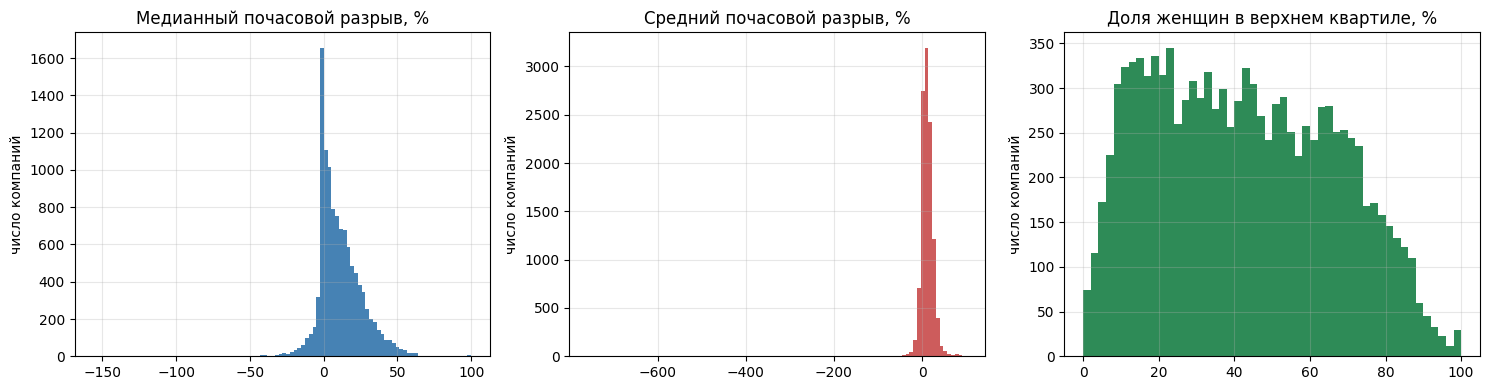

In [217]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(data['DiffMedianHourlyPercent'], bins=100, color='steelblue')
axes[0].set_title('Медианный почасовой разрыв, %')
axes[1].hist(data['DiffMeanHourlyPercent'], bins=100, color='indianred')
axes[1].set_title('Средний почасовой разрыв, %')
axes[2].hist(data['FemaleTopQuartile'], bins=50, color='seagreen')
axes[2].set_title('Доля женщин в верхнем квартиле, %')
for ax in axes: ax.set_ylabel('число компаний')
plt.tight_layout(); plt.show()

## 3. Предобработка данных


In [218]:
log = []
def note(step, n, comment):
    log.append({'шаг': step, 'затронуто строк': int(n), 'комментарий': comment})
    print(f'[{step}] {int(n)} строк - {comment}')

data['DueDate'] = pd.to_datetime(data['DueDate'])
data['DateSubmitted'] = pd.to_datetime(data['DateSubmitted'])
note('Типы', len(data), 'DueDate, DateSubmitted → datetime')

[Типы] 11198 строк - DueDate, DateSubmitted → datetime


### 3.1 Обработка пропусков

Количество пропусков по столбцам приведено в п. 2.5: пропуски есть в 8 столбцах из 27, ключевые показатели (почасовой разрыв и квартили) заполнены полностью. Чтобы выбрать стратегию, сначала выясним **причину** каждого пропуска.

Для этого понадобится признак **сектора**. В данных его нет, но он однозначно определяется по сроку подачи (см. п. 2.1): у госсектора — 31 марта, у частного — 5 апреля.

In [219]:
data['sector'] = np.where(data['DueDate'].dt.month == 3, 'Госсектор', 'Частный')
note('Признаки', len(data), 'sector: госсектор (срок 31.03) / частный (срок 05.04)')

no_bonus_gap = data['DiffMeanBonusPercent'].isna()
someone_no_bonus = (data['MaleBonusPercent'] == 0) | (data['FemaleBonusPercent'] == 0)
print(f'\nПропусков бонусного разрыва: {no_bonus_gap.sum()}, '
      f'из них хотя бы один пол без бонусов: {(no_bonus_gap & someone_no_bonus).sum()}')

print('\nДоля пропусков по сектору, %:')
display(data[['ResponsiblePerson', 'CompanyNumber', 'SicCodes', 'CompanyLinkToGPGInfo', 'PostCode']]
        .isna().groupby(data['sector']).mean().mul(100).round(1))


[Признаки] 11198 строк - sector: госсектор (срок 31.03) / частный (срок 05.04)

Пропусков бонусного разрыва: 2747, из них хотя бы один пол без бонусов: 2747

Доля пропусков по сектору, %:


,ResponsiblePerson,CompanyNumber,SicCodes,CompanyLinkToGPGInfo,PostCode
sector,,,,,
Госсектор,99.9,68.1,20.1,56.3,0.2
Частный,0.0,2.1,6.3,44.5,0.6


**Причины пропусков и выбранная стратегия**

| Столбец | Пропусков (п. 2.5) | Причина | Нужен для цели? | Стратегия |
|---|---|---|---|---|
| `DiffMeanBonusPercent`, `DiffMedianBonusPercent` | 2 747 | **Структурная:** в 100% случаев хотя бы один пол бонусов не получал, разрыв не вычисляется | Да (H5) | **Не заполнять.** Медиана создала бы разрыв там, где бонусов нет. Специальная метка `bonus_status` |
| `CompanyLinkToGPGInfo` | 5 209 | Необязательное поле | Да (H7), но важен только факт наличия | **Специальная метка:** флаг `has_gpg_link`, сам столбец удалить |
| `SicCodes` | 972 | Поле не обязательное; в госсекторе пропусков втрое больше (20% против 6%) | Да — отрасль один из ключевых факторов | **Заполнить по связанному столбцу:** отрасль по ключевым словам в названии; остальным — метка «Не определена» |
| `ResponsiblePerson` | 1 949 | От госсектора не требуется (99,9% пропусков там) | Нет | **Удалить столбец** (персональные данные) |
| `CompanyNumber` | 1 522 | У госорганов и благотворительных организаций нет номера Companies House | Нет (нужен только при удалении дубликатов) | Оставить как есть |
| `PostCode`, `Address` | 59 / 34 | В основном зарубежные головные офисы | Регион — второстепенный фактор, пропуски 0,5% | **Не заполнять:** регион получит метку «Не определён»; `Address` удалить |

Заполнение средним или медианой **не применяется**: в числовых показателях единственные пропуски — структурные, и любое заполнение исказило бы данные.

In [220]:
data['bonus_status'] = np.select(
    [(data['MaleBonusPercent'] == 0) & (data['FemaleBonusPercent'] == 0),
     (data['MaleBonusPercent'] == 0) | (data['FemaleBonusPercent'] == 0)],
    ['нет бонусов', 'бонусы у одного пола'], default='бонусы у обоих')
note('Пропуски', no_bonus_gap.sum(), 'Бонусный разрыв: NaN оставлены (структурные), добавлена метка bonus_status')

data['has_gpg_link'] = data['CompanyLinkToGPGInfo'].notna().astype(int)
note('Пропуски', (data['has_gpg_link'] == 0).sum(), 'CompanyLinkToGPGInfo → флаг has_gpg_link (1 - ссылка есть, 0 - нет)')

print(data['bonus_status'].value_counts())

[Пропуски] 2747 строк - Бонусный разрыв: NaN оставлены (структурные), добавлена метка bonus_status
[Пропуски] 5209 строк - CompanyLinkToGPGInfo → флаг has_gpg_link (1 - ссылка есть, 0 - нет)
бонусы у обоих          8312
нет бонусов             2632
бонусы у одного пола     254
Name: bonus_status, dtype: int64


Бонусный разрыв не заполнялся, и это сознательное решение: пропуск означает, что бонусов нет, а не потерю данных


#### Отрасль

Секция классификатора SIC определяется по первому коду; служебный код `1` (метка госсектора) пропускается. Если кода нет — или есть только `1` — отрасль определяется по ключевым словам в названии организации (школы, NHS, советы, юридические фирмы и т.п.).

In [221]:
SECTIONS = [(1, 3, 'Сельское хозяйство'), (5, 9, 'Добыча'), (10, 33, 'Производство'), (35, 35, 'Энергетика'),
            (36, 39, 'Водоснабжение, отходы'), (41, 43, 'Строительство'), (45, 47, 'Торговля'), (49, 53, 'Транспорт'),
            (55, 56, 'Гостиницы и общепит'), (58, 63, 'IT и связь'), (64, 66, 'Финансы'), (68, 68, 'Недвижимость'),
            (69, 75, 'Проф. услуги'), (77, 82, 'Адм. услуги'), (84, 84, 'Госуправление'), (85, 85, 'Образование'),
            (86, 88, 'Здравоохранение и соцуслуги'), (90, 93, 'Культура и спорт'), (94, 99, 'Прочие услуги')]

def section_from_sic(raw):
    if pd.isna(raw):
        return np.nan
    codes = [c for c in raw.replace('\n', '').replace(' ', '').split(',') if c and c != '1']
    if not codes:
        return np.nan
    div = int(codes[0].zfill(5)[:2])
    return next((name for a, b, name in SECTIONS if a <= div <= b), np.nan)

KEYWORDS = [('Образование',  ['ACADEMY', 'SCHOOL', 'COLLEGE', 'UNIVERSITY', 'EDUCATION', 'LEARN', 'DIOCESE']),
            ('Здравоохранение и соцуслуги', ['NHS', 'HOSPITAL', 'HEALTH', 'CARE', 'HOSPICE']),
            ('Госуправление', ['COUNCIL', 'AUTHORITY', 'POLICE', 'FIRE', 'GOVERNMENT', 'MINISTRY', 'DEPARTMENT']),
            ('Недвижимость',  ['HOUSING', 'HOMES']),
            ('Проф. услуги',  ['LLP', 'SOLICITORS', 'ARCHITECTS', 'SURVEYORS', 'ACCOUNTANTS']),
            ('Финансы',       ['BANK', 'BUILDING SOCIETY', 'INSURANCE', 'CAPITAL', 'INVESTMENT'])]

def section_from_name(name, sector):
    name = name.upper()
    for sec, words in KEYWORDS:
        if any(w in name for w in words):
            return sec
    if sector == 'Госсектор' and 'TRUST' in name:
        return 'Образование'
    return 'Не определена'

data['industry'] = data['SicCodes'].apply(section_from_sic)
no_sic = data['industry'].isna()
data.loc[no_sic, 'industry'] = [section_from_name(n, s) for n, s in
                                zip(data.loc[no_sic, 'EmployerName'], data.loc[no_sic, 'sector'])]
unknown = (data['industry'] == 'Не определена').sum()

print(f'Без SIC-кода (или только код 1): {no_sic.sum()}; отрасль определена по названию: {no_sic.sum() - unknown}')
note('Пропуски', no_sic.sum() - unknown, 'Отрасль без SIC-кода определена по ключевым словам в названии')
note('Пропуски', unknown, 'Отрасль не определилась ни по SIC, ни по названию → метка "Не определена@')
print(); print(data['industry'].value_counts())

Без SIC-кода (или только код 1): 1050; отрасль определена по названию: 798
[Пропуски] 798 строк - Отрасль без SIC-кода определена по ключевым словам в названии
[Пропуски] 252 строк - Отрасль не определилась ни по SIC, ни по названию → метка "Не определена@

Образование                    1612
Производство                   1350
Адм. услуги                    1148
Здравоохранение и соцуслуги    1035
Проф. услуги                    972
Торговля                        949
IT и связь                      612
Гостиницы и общепит             551
Финансы                         530
Госуправление                   510
Транспорт                       408
Строительство                   321
Не определена                   252
Культура и спорт                245
Недвижимость                    225
Прочие услуги                   211
Водоснабжение, отходы            82
Энергетика                       70
Сельское хозяйство               62
Добыча                           53
Name: industry, dtype:

Отрасль не была определена у 1 050 организаций: 972 без SIC-кода из п. 2.5 и ещё 78 только с кодом `1`. 

По названию удалось определить 798 из них, в основном школы, академические тресты и учреждения NHS. Без этого они выпали бы из анализа по отраслям. 

Неопределённой отрасль осталась у 252 организаций (2%). 

### 3.2 Работа с дубликатами

Дубликаты найдены в п. 2.5: полных дубликатов и повторов по ID нет, но есть **51 лишняя копия** — записи с одинаковым индексом и идентичными до сотых долей 14 показателями. Сюда входят повторная регистрация одной организации (CHRISTADELPHIAN CARE HOMES) и групповые отчёты, поданные от каждого юрлица группы (например, четыре компании ACCOMPLISH GROUP).

**Решение — удалить копии, оставив одну запись из группы.** Совпадение всех 14 чисел случайным быть не может: это одни и те же сотрудники. Если оставить копии, такие группы получат в анализе двойной–четверной вес, а наблюдения перестанут быть независимыми. Из группы оставляем запись с номером компании, если он есть.

Совпадения показателей **без** совпадения адреса не удаляем: разные компании могут случайно совпасть, например при нулевых значениях.

In [222]:
n_before = len(data)
metrics = data.columns[6:20].tolist()

data = (data.assign(_no_num=data['CompanyNumber'].isna())
            .sort_values(['_no_num', 'EmployerId'])
            .drop_duplicates(subset=['PostCode'] + metrics, keep='first')
            .drop(columns='_no_num')
            .sort_index())

note('Дубликаты', n_before - len(data), 'Одинаковый индекс + 14 идентичных показателей: оставлена 1 запись из группы')
print(f'Строк было {n_before}, стало {len(data)}')

[Дубликаты] 51 строк - Одинаковый индекс + 14 идентичных показателей: оставлена 1 запись из группы
Строк было 11198, стало 11147


### 3.3 Выбросы

В п. 2.6 видны подозрительные значения: средний почасовой разрыв −757% и медианный разрыв в бонусах −999 999 999.

Разрыв = (М − Ж) / М × 100, где М и Ж — почасовые ставки мужчин и женщин. Отсюда три правила:
- **Сверху граница строгая: ≥ 100% невозможно.** Это означало бы, что ставка женщин равна нулю или отрицательна.
- **Если в штате один пол, разрыв не определён** — сравнивать не с кем.
- **Снизу строгой границы нет:** если женщины получают в 8,6 раза больше мужчин, разрыв равен −757%. Поэтому отрицательные значения не отсекаем по порогу, а проверяем на **согласованность** со средним/медианным разрывом того же отчёта. Математически они могут расходиться сколь угодно сильно (одна сверхвысокая зарплата сдвигает среднее, но не медиану), однако на практике у 99,9% компаний расхождение меньше 85 процентных пунктов — даже у футбольных клубов с огромными зарплатами игроков оно не превышает 88 п.п. Расхождение более 100 п.п. выходит далеко за реальный диапазон, поэтому считаем его ошибкой ввода — тем более что у таких компаний состав квартилей не показывает перекоса, который мог бы его объяснить.


In [223]:
pct_cols = data_raw.columns[6:20]
bounds = {c: (0, 100) for c in pct_cols if 'Quartile' in c or c in ['MaleBonusPercent', 'FemaleBonusPercent']}
bounds.update({'DiffMeanHourlyPercent': (-np.inf, 99.99), 'DiffMedianHourlyPercent': (-np.inf, 99.99),
               'DiffMeanBonusPercent': (-np.inf, 100), 'DiffMedianBonusPercent': (-np.inf, 100)})

check = pd.DataFrame({
    'допустимо': {c: f'[{lo}; {hi}]' for c, (lo, hi) in bounds.items()},
    'мин': data_raw[pct_cols].min(), 'макс': data_raw[pct_cols].max(),
    'вне диапазона': {c: int(((data_raw[c] < lo) | (data_raw[c] > hi)).sum()) for c, (lo, hi) in bounds.items()},
    'ниже −100': (data_raw[pct_cols] < -100).sum(),
    'равно 100': (data_raw[pct_cols] == 100).sum()})
check

,допустимо,мин,макс,вне диапазона,ниже −100,равно 100
DiffMeanBonusPercent,[-inf; 100],-4.900000e+03,100.0,0,255,124
DiffMeanHourlyPercent,[-inf; 99.99],-7.570000e+02,100.0,3,4,3
DiffMedianBonusPercent,[-inf; 100],-1.000000e+09,100.0,0,391,129
DiffMedianHourlyPercent,[-inf; 99.99],-1.561400e+02,100.0,5,2,5
FemaleBonusPercent,[0; 100],0.000000e+00,100.0,0,0,197
FemaleLowerMiddleQuartile,[0; 100],0.000000e+00,100.0,0,0,47
FemaleLowerQuartile,[0; 100],0.000000e+00,100.0,0,0,40
FemaleTopQuartile,[0; 100],0.000000e+00,100.0,0,0,21
FemaleUpperMiddleQuartile,[0; 100],0.000000e+00,100.0,0,0,24
MaleBonusPercent,[0; 100],0.000000e+00,100.0,0,0,151


Границы зависят от смысла показателя:
- **Доли** (бонусы по полу, состав квартилей) должны лежать в [0; 100] — нарушений нет.
- **Почасовой разрыв** при наличии в штате обоих полов не может быть ≥ 100% (тогда ставка женщин равна нулю); если в штате один пол, разрыв не определён вовсе и любое указанное значение — условность. Снизу строгого ограничения нет, поэтому отрицательные значения проверяются на согласованность среднего и медианного разрыва.
- **Бонусный разрыв** может равняться 100% (женщины не получали бонусов) и быть ниже −100% (бонусы на малых группах распределены неравномерно), поэтому такие значения не являются ошибкой. Исключение — служебная заглушка −999 999 999.

Стандартный метод **IQR здесь не подходит**:


In [224]:
s = data['DiffMedianHourlyPercent']
q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
print(f'Границы IQR: [{q1 - 1.5*iqr:.1f}; {q3 + 1.5*iqr:.1f}] → вне границ {((s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)).sum()} компаний')

Границы IQR: [-27.0; 46.8] → вне границ 315 компаний


IQR отбросил бы 315 компаний с разрывом больше 47%. Такой разрыв велик, но правдоподобен: например, в авиации и финансах. Именно эти компании важнее всего для цели исследования, поэтому выбросы отбираем по предметным границам.

In [225]:
hourly = ['DiffMeanHourlyPercent', 'DiffMedianHourlyPercent']
bonus = ['DiffMeanBonusPercent', 'DiffMedianBonusPercent']
fq = ['FemaleLowerQuartile', 'FemaleLowerMiddleQuartile', 'FemaleUpperMiddleQuartile', 'FemaleTopQuartile']
share_raw = data_raw[fq].mean(axis=1)
n_start = len(data)

def remove_rows(mask, comment):
    in_data = data.index.isin(data_raw.index[mask])
    note('Выбросы', in_data.sum(), comment)
    return data[~in_data].copy()

**1. В штате один пол** — разрыв не определён, указанное значение — условность.

In [226]:
one_gender = (share_raw == 0) | (share_raw == 100)
display(data_raw.loc[one_gender, ['EmployerName'] + hourly].assign(доля_женщин=share_raw[one_gender]))
data = remove_rows(one_gender, 'В штате один пол — разрыв не определён, строки удалены')

,EmployerName,DiffMeanHourlyPercent,DiffMedianHourlyPercent,доля_женщин
2348,Corseford School,0.0,0.0,100.0
4535,HOPSCOTCH DAY NURSERIES (BOTLEY) LTD,-100.0,-100.0,100.0
4537,HOPSCOTCH DAY NURSERIES (FAREHAM) LTD,0.0,0.0,100.0
4538,HOPSCOTCH DAY NURSERIES (GOSPORT) LTD,0.0,0.0,100.0
4539,HOPSCOTCH DAY NURSERIES (LEE ON SOLENT) LTD,0.0,0.0,100.0
4540,HOPSCOTCH DAY NURSERIES (PORTSWOOD) LIMITED,0.0,0.0,100.0
4542,HOPSCOTCH DAY NURSERIES (SHOLING) LTD.,0.0,0.0,100.0
4543,HOPSCOTCH DAY NURSERIES (TITCHFIELD) LTD,0.0,0.0,100.0
8062,ROBERT PRICE & SONS LIMITED,100.0,100.0,0.0


[Выбросы] 4 строк - В штате один пол — разрыв не определён, строки удалены


**2. Разрыв ≥ 100% при обоих полах в штате** — ставка женщин была бы нулевой.

In [227]:
impossible = (data_raw[hourly] >= 100).any(axis=1) & ~one_gender
display(data_raw.loc[impossible, ['EmployerName'] + hourly].assign(доля_женщин=share_raw[impossible].round(1)))
data = remove_rows(impossible, 'Почасовой разрыв ≥ 100% при обоих полах — ставка женщин была бы ≤ 0, строки удалены')

,EmployerName,DiffMeanHourlyPercent,DiffMedianHourlyPercent,доля_женщин
1320,BRADWELL HALL NURSING HOME LIMITED,-20.0,100.0,85.0
1612,CALEDONIAN HERITABLE LIMITED,100.0,100.0,50.1
5826,LUDDON CONSTRUCTION LIMITED,9.9,100.0,9.4
6438,MPD FM LIMITED,100.0,100.0,10.7


[Выбросы] 4 строк - Почасовой разрыв ≥ 100% при обоих полах — ставка женщин была бы ≤ 0, строки удалены


**3. Средний и медианный разрыв противоречат друг другу** (расхождение более 100 п.п.).

In [228]:
gap_diff = (data_raw['DiffMeanHourlyPercent'] - data_raw['DiffMedianHourlyPercent']).abs()
inconsistent = (gap_diff > 100) & ~one_gender & ~impossible
print(f'Расхождение у 99,9% компаний — до {gap_diff.quantile(0.999):.0f} п.п.')
display(data_raw.loc[inconsistent, ['EmployerName'] + hourly].assign(расхождение=gap_diff[inconsistent].round(1)))
data = remove_rows(inconsistent, 'Средний и медианный разрыв расходятся > 100 п.п. — ошибка ввода, строки удалены')

Расхождение у 99,9% компаний — до 84 п.п.


,EmployerName,DiffMeanHourlyPercent,DiffMedianHourlyPercent,расхождение
2261,CONCEPT RECRUITMENT GROUP LIMITED,-143.20,-2.62,140.6
2752,DIGITAL MEDICAL SUPPLY UK LIMITED,-757.00,52.00,809.0
3516,FIRMENICH UK LIMITED,24.65,-156.14,180.8
8957,ST DUNSTAN'S EDUCATIONAL FOUNDATION,-171.00,4.00,175.0
10095,TOTAL RECRUIT LTD,-458.98,0.02,459.0


[Выбросы] 5 строк - Средний и медианный разрыв расходятся > 100 п.п. — ошибка ввода, строки удалены


**4. Служебная заглушка в бонусах.**

In [229]:
sentinel = data_raw['DiffMedianBonusPercent'] <= -1e6
display(data_raw.loc[sentinel, ['EmployerName', 'DiffMedianBonusPercent']])
data.loc[data.index.isin(data_raw.index[sentinel]), 'DiffMedianBonusPercent'] = np.nan
note('Выбросы', sentinel.sum(), 'DiffMedianBonusPercent = −999 999 999 (служебная заглушка) → NaN')

,EmployerName,DiffMedianBonusPercent
337,ALLIANCE DISPOSABLES LIMITED,-999999999.0


[Выбросы] 1 строк - DiffMedianBonusPercent = −999 999 999 (служебная заглушка) → NaN


**5. Бонус получал только один пол** - бонусный разрыв не определён.

Разрыв в бонусах считается только среди получивших бонус. Если среди получателей нет женщин (или мужчин), сравнивать не с кем. В таких отчётах одна и та же ситуация заполнена по-разному — 100%, 0% или другое число, — поэтому все эти значения заменяем на NaN

In [230]:
one_sex_bonus = (((data_raw['MaleBonusPercent'] == 0) | (data_raw['FemaleBonusPercent'] == 0))
                 & data_raw['DiffMeanBonusPercent'].notna())
print('Что указано в разрыве у таких компаний:')
print(data_raw.loc[one_sex_bonus, 'DiffMeanBonusPercent'].value_counts().to_string())
data.loc[data.index.isin(data_raw.index[one_sex_bonus]), bonus] = np.nan
note('Выбросы', one_sex_bonus.sum(), 'Бонус получал только один пол — разрыв не определён (указаны 100, 0 и др.) → NaN')

filled = data['DiffMeanBonusPercent'].notna().map({True: 'разрыв указан', False: 'разрыв пустой'})
pd.crosstab(data['bonus_status'], filled)

Что указано в разрыве у таких компаний:
 100.0    120
 0.0       15
 87.8       1
 53.0       1
 7.0        1
-100.0      1
[Выбросы] 139 строк - Бонус получал только один пол — разрыв не определён (указаны 100, 0 и др.) → NaN


DiffMeanBonusPercent,разрыв пустой,разрыв указан
bonus_status,,
бонусы у обоих,0,8262
бонусы у одного пола,254,0
нет бонусов,2618,0


Бонусный разрыв указан ровно у компаний, где бонусы получали оба пола, и пуст у всех остальных — данные и метка `bonus_status` согласованы.

**6. Бонусный разрыв ниже −100%** — возможен на малых группах, оставляем, но для статистики обрезаем.

In [231]:
low_bonus = (data[bonus] < -100).any(axis=1)
print('Самые низкие значения:', data['DiffMeanBonusPercent'].nsmallest(5).tolist())
for c in bonus:
    data[c + '_clip'] = data[c].clip(lower=-100)
note('Выбросы', low_bonus.sum(), 'Бонусный разрыв < −100%: оставлен; добавлены версии *_clip, обрезанные на −100')

Самые низкие значения: [-4900.0, -4880.0, -3934.29, -2889.8, -2888.7]
[Выбросы] 541 строк - Бонусный разрыв < −100%: оставлен; добавлены версии *_clip, обрезанные на −100


In [232]:
print(f'Строк было {n_start}, стало {len(data)} (удалено {n_start - len(data)})')
display(pd.DataFrame({
    'среднее до': data_raw[hourly].mean(), 'среднее после': data[hourly].mean(),
    'мин до': data_raw[hourly].min(), 'мин после': data[hourly].min(),
    'макс до': data_raw[hourly].max(), 'макс после': data[hourly].max()}).round(2))

Строк было 11147, стало 11134 (удалено 13)


,среднее до,среднее после,мин до,мин после,макс до,макс после
DiffMeanHourlyPercent,11.50,11.63,-757.00,-91.28,100.0,97.0
DiffMedianHourlyPercent,11.02,11.02,-156.14,-124.56,100.0,91.3


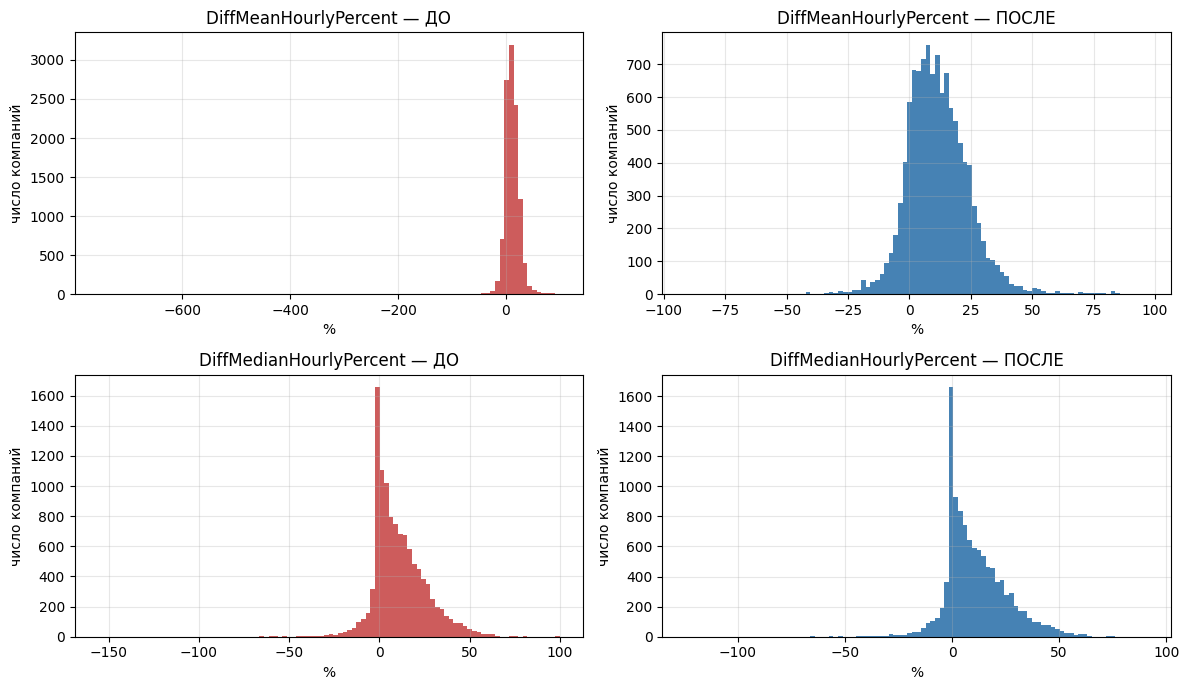

In [233]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for row, col in enumerate(hourly):
    axes[row, 0].hist(data_raw[col], bins=100, color='indianred'); axes[row, 0].set_title(f'{col} — ДО')
    axes[row, 1].hist(data[col], bins=100, color='steelblue');     axes[row, 1].set_title(f'{col} — ПОСЛЕ')
for ax in axes.flat: ax.set_xlabel('%'); ax.set_ylabel('число компаний')
plt.tight_layout(); plt.show()

**Вывод**
- **Однополые компании (4 строки после удаления дубликатов) удалены.** В исходных данных 9 организаций, где все сотрудники одного пола. Разрыв у них не определён: сравнивать не с кем. В одной и той же ситуации указаны разные значения — 0, −100 и +100%, т.е. это условность, а не измерение; нули к тому же ошибочно попали бы в категорию «паритет».
- **Удалены 4 строки с разрывом ≥ 100%** при обоих полах в штате: это означало бы нулевую ставку женщин.
- **Удалены 5 строк, где средний и медианный разрыв противоречат друг другу** (расхождение 141–809 п.п., в трёх случаях — разные знаки). Отрицательные значения сами по себе не удалялись: например, у NCR LIMITED медианный разрыв −124,6%, но он согласуется со средним (−69,9%) и с составом квартилей — женщины сосредоточены в верхних квартилях. Это реальный случай.
- **Заглушка −999 999 999 заменена на NaN**: это служебное значение, а не наблюдение.
- **19 противоречивых бонусных значений заменены на NaN:** если женщины бонусов не получали, разрыв по формуле обязан быть 100%. Строки сохранены, потому что остальные показатели в них корректны.
- **Бонусный разрыв ниже −100% (541 компания) оставлен:** на малых группах это возможно (2 женщины-руководителя с бонусом против 50 рабочих-мужчин дают −4900%). Для статистики добавлены версии `*_clip`, обрезанные на −100, чтобы единичные значения не определяли средние.
- После очистки средний почасовой разрыв лежит в диапазоне от −91,3% до 97,0%, медианный — от −124,6% до 91,3%. Средние по выборке практически не изменились (11,50 → 11,63% и 11,02 → 11,02%): удалено всего 13 строк из 11 тысяч.

### 3.4 Новые признаки и удаление ненужных

Для проверки гипотез H1–H7 нужны признаки, которых в исходных данных нет.

| Признак | Как получен | Гипотеза |
|---|---|---|
| `sector` | по сроку подачи (п. 3.1) | H3 |
| `industry` | по SIC-коду или названию (п. 3.1) | H2 |
| `bonus_status`, `has_gpg_link` | метки вместо пропусков (п. 3.1) | H5, H7 |
| `gap_category` | категория медианного разрыва A–E | распределение компаний по величине разрыва |
| `size_ord`, `size_category` | порядковый номер и укрупнённые группы размера | H4 |
| `female_share` | среднее долей женщин по 4 квартилям (квартили равны по численности) | доля женщин в штате |
| `workforce_type` | преимущественно мужской / смешанный / женский коллектив | сравнение типов персонала |
| `vertical_segregation` | доля женщин в нижнем квартиле − в верхнем | насколько женщины сосредоточены внизу шкалы оплаты (H1) |
| `top_q_category` | доля женщин в верхнем квартиле | H1 |
| `region` | по буквам почтового района | H6 |

Категории разрыва:

| Диапазон, % | Категория |
|---|---|
| < −5 | E - в пользу женщин |
| −5 … 5 | D - паритет |
| 5 … 15 | C - умеренный |
| 15 … 25 | B - высокий |
| ≥ 25 | A - очень высокий |

In [234]:
gap_bins = [-np.inf, -5, 5, 15, 25, np.inf]
gap_labels = ['E - в пользу женщин', 'D - паритет', 'C - умеренный', 'B - высокий', 'A - очень высокий']
data['gap_category'] = pd.cut(data['DiffMedianHourlyPercent'], bins=gap_bins, labels=gap_labels, right=False)
note('Признаки', len(data), 'gap_category: категория медианного разрыва A–E')
print(data['gap_category'].value_counts().sort_index())

[Признаки] 11134 строк - gap_category: категория медианного разрыва A–E
E - в пользу женщин     613
D - паритет            3938
C - умеренный          2879
B - высокий            1934
A - очень высокий      1770
Name: gap_category, dtype: int64


In [235]:
fq = ['FemaleLowerQuartile', 'FemaleLowerMiddleQuartile', 'FemaleUpperMiddleQuartile', 'FemaleTopQuartile']
data['female_share'] = data[fq].mean(axis=1)    # квартили равны по численности → доля женщин в штате
data['workforce_type'] = pd.cut(data['female_share'], [0, 40, 60, 100.01], right=False,
                                labels=['преимущественно мужской', 'смешанный', 'преимущественно женский'])
data['vertical_segregation'] = data['FemaleLowerQuartile'] - data['FemaleTopQuartile']
data['top_q_category'] = pd.cut(data['FemaleTopQuartile'], [0, 20, 40, 60, 80, 100.01], right=False,
                                labels=['0–20%', '20–40%', '40–60%', '60–80%', '80–100%'])
note('Признаки', len(data), 'female_share, workforce_type, vertical_segregation, top_q_category')
print(data['workforce_type'].value_counts())

[Признаки] 11134 строк - female_share, workforce_type, vertical_segregation, top_q_category
преимущественно мужской    4217
преимущественно женский    3850
смешанный                  3067
Name: workforce_type, dtype: int64


**Размер компании** `EmployerSize` задан интервалами (п. 2.1), пропусков нет (п. 2.5). Проверим значения:

In [236]:
size_order = ['Less than 250', '250 to 499', '500 to 999', '1000 to 4999', '5000 to 19,999', '20,000 or more']
print('Значения вне списка:', set(data['EmployerSize']) - set(size_order))
print(data['EmployerSize'].value_counts().reindex(size_order))

Значения вне списка: set()
Less than 250      435
250 to 499        4800
500 to 999        2855
1000 to 4999      2431
5000 to 19,999     546
20,000 or more      67
Name: EmployerSize, dtype: int64


Значения корректны: шесть интервалов, опечаток нет. Для анализа:
- **«Less than 250» оставляем:** это добровольные отчёты (п. 2.1), они корректны, хотя и подвержены самоотбору — учтём это при выводах.
- **«5000 to 19,999» и «20,000 or more» объединяем в «5000+»:** в последней группе около 70 компаний, слишком мало для надёжного сравнения медиан.
- Создаём `size_ord` (порядковый номер интервала, 0–5) для корреляции и `size_category` (5 групп) для сводных таблиц.

In [237]:
data['size_ord'] = data['EmployerSize'].map({s: i for i, s in enumerate(size_order)})
data['size_category'] = pd.Categorical(
    data['EmployerSize'].map({'Less than 250': 'до 250', '250 to 499': '250–499', '500 to 999': '500–999',
                              '1000 to 4999': '1000–4999', '5000 to 19,999': '5000+', '20,000 or more': '5000+'}),
    categories=['до 250', '250–499', '500–999', '1000–4999', '5000+'], ordered=True)
note('Признаки', len(data), 'size_ord (порядковый номер интервала), size_category (5 групп, 5000+ объединены)')
print(data['size_category'].value_counts().sort_index())

[Признаки] 11134 строк - size_ord (порядковый номер интервала), size_category (5 групп, 5000+ объединены)
до 250        435
250–499      4800
500–999      2855
1000–4999    2431
5000+         613
Name: size_category, dtype: int64


In [238]:
import re

SCOT = {'AB','DD','DG','EH','FK','G','HS','IV','KA','KW','KY','ML','PA','PH','TD','ZE'}
WALES = {'CF','LD','LL','NP','SA'}
LONDON = {'E','EC','N','NW','SE','SW','W','WC'}

def region(pc):
    m = re.match(r'^\s*([A-Z]{1,2})\d', str(pc).upper())
    if not m:
        return 'Не определён'
    area = m.group(1)
    if area == 'BT': return 'Сев. Ирландия'
    if area in SCOT: return 'Шотландия'
    if area in WALES: return 'Уэльс'
    if area in LONDON: return 'Лондон'
    return 'Англия (кроме Лондона)'

data['region'] = data['PostCode'].apply(region)
note('Признаки', len(data), 'region по буквам почтового района')
note('Пропуски', (data['region'] == 'Не определён').sum(), 'PostCode пуст или не британский → регион «Не определён»')
print(); print(data['region'].value_counts())

[Признаки] 11134 строк - region по буквам почтового района
[Пропуски] 68 строк - PostCode пуст или не британский → регион «Не определён»

Англия (кроме Лондона)    7688
Лондон                    2525
Шотландия                  554
Уэльс                      264
Не определён                68
Сев. Ирландия               35
Name: region, dtype: int64


**Удаление ненужных столбцов.** Перед удалением мужских квартилей проверим, что они действительно избыточны, т.е. в каждой паре М + Ж = 100:

In [239]:
quart = ['LowerQuartile', 'LowerMiddleQuartile', 'UpperMiddleQuartile', 'TopQuartile']
print('Пар квартилей, где М + Ж ≠ 100:',
      sum(((data['Male' + q] + data['Female' + q] - 100).abs() > 0.5).sum() for q in quart))

to_drop = ['Address', 'CompanyLinkToGPGInfo', 'ResponsiblePerson', 'CurrentName',
           'MaleLowerQuartile', 'MaleLowerMiddleQuartile', 'MaleUpperMiddleQuartile', 'MaleTopQuartile']
data = data.drop(columns=to_drop, errors='ignore')
note('Удаление', len(to_drop), 'Удалены столбцы: Address, CompanyLinkToGPGInfo, ResponsiblePerson, CurrentName, Male*Quartile')

Пар квартилей, где М + Ж ≠ 100: 0
[Удаление] 8 строк - Удалены столбцы: Address, CompanyLinkToGPGInfo, ResponsiblePerson, CurrentName, Male*Quartile


| Удалено | Причина |
|---|---|
| `Address` | Свободный текст; для региона достаточно индекса |
| `CompanyLinkToGPGInfo` | Заменён флагом `has_gpg_link` |
| `ResponsiblePerson` | Персональные данные, для анализа не нужны |
| `CurrentName` | Дублирует `EmployerName` |
| `Male*Quartile` (4 столбца) | Строго равны 100 − `Female*Quartile` |

In [240]:
display(pd.DataFrame(log))

print(f'Было:  {data_raw.shape[0]:,} строк × {data_raw.shape[1]} столбцов')
print(f'Стало: {data.shape[0]:,} строк × {data.shape[1]} столбцов')
data.to_csv('gpg_2025_26_clean.csv', index=False)

,шаг,затронуто строк,комментарий
0,Типы,11198,"DueDate, DateSubmitted → datetime"
1,Признаки,11198,sector: госсектор (срок 31.03) / частный (срок...
2,Пропуски,2747,"Бонусный разрыв: NaN оставлены (структурные), ..."
3,Пропуски,5209,CompanyLinkToGPGInfo → флаг has_gpg_link (1 - ...
4,Пропуски,798,Отрасль без SIC-кода определена по ключевым сл...
5,Пропуски,252,"Отрасль не определилась ни по SIC, ни по назва..."
6,Дубликаты,51,Одинаковый индекс + 14 идентичных показателей:...
7,Выбросы,4,"В штате один пол — разрыв не определён, строки..."
8,Выбросы,4,Почасовой разрыв ≥ 100% при обоих полах — став...
9,Выбросы,5,Средний и медианный разрыв расходятся > 100 п....


Было:  11,198 строк × 27 столбцов
Стало: 11,134 строк × 33 столбцов


### 3.5 Выводы

- **Пропуски.** Большинство пропусков не случайны и следуют из правил отчётности: бонусов нет, поле не требуется от госсектора, поле необязательное. Поэтому числовые пропуски не заполнялись, а заменялись метками. Заполнение направлено туда, где пропуск мешает цели: **отрасль определена по названию для 798 организаций**, и неопределённой она осталась только у 2%.
- **Дубликаты.** Удалена **51 скрытая копия**: групповые отчёты и одна повторная регистрация. Иначе одни и те же сотрудники учитывались бы по несколько раз.
- **Выбросы.** Удалены 13 строк: 4 однополые компании (разрыв не определён), 4 с невозможным разрывом ≥ 100% и 5 с противоречием между средним и медианным разрывом. Служебная заглушка −999 999 999 и бонусный разрыв у 139 компаний, где бонус получал только один пол (разрыв не определён), заменены на NaN.
- **Признаки.** Добавлены 14 признаков, каждый нужен для проверки гипотез; удалены 8 избыточных столбцов.
- **Итог:** 11 134 строки (99,4% исходных) и 33 столбца.

**Проблемы и рекомендации сборщику данных**

| Проблема | Рекомендация |
|---|---|
| Невозможные или противоречивые значения почасового разрыва (100% при обоих полах; средний −757% при медианном +52%) | Проверка в форме ввода: разрыв < 100%; предупреждение, если средний и медианный разрыв расходятся более чем на 100 п.п. |
| Однополые компании указывают разрыв как 0, −100 или 100% | Если в штате один пол, поле разрыва не заполняется, а отмечается «не применимо» |
| Служебная заглушка −999 999 999 в публичных данных | Отдельная отметка «нет данных» вместо числа |
| Если бонус получал один пол, бонусный разрыв заполняется как 100%, 0% или не заполняется | Поле бонусного разрыва блокировать с отметкой «не применимо», если доля получателей одного из полов равна 0 |
| 51 копия групповых отчётов, повторная регистрация | Поле «отчёт группы компаний» с указанием материнской компании; проверка дублей при регистрации |
| 9% записей без SIC-кода; код «1» вместо сектора | Выпадающий список SIC с автодополнением; сектор — отдельное поле |